# Machine Learning - Atividade 03 - Avaliação

## *José Diniz Junior* - RA: 183134

#########################################################################################################################################################################


## Imports

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, cross_val_score, ShuffleSplit

from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import log_loss
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif 

import datetime as dt

import warnings
warnings.filterwarnings(action='ignore')

## Leitura do arquivo 'avaliacao.csv'

In [2]:
df = pd.read_csv('avaliacao.csv')
df.head()

,action_type,combined_shot_type,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,...,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,team_id,team_name,game_date,matchup,opponent,shot_id
0,Jump Shot,Jump Shot,10,20000012,33.9723,167,72,-118.1028,10,1,...,2PT Field Goal,Right Side(R),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,1
1,Jump Shot,Jump Shot,12,20000012,34.0443,-157,0,-118.4268,10,1,...,2PT Field Goal,Left Side(L),Mid-Range,8-16 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,2
2,Jump Shot,Jump Shot,35,20000012,33.9093,-101,135,-118.3708,7,1,...,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,3
3,Jump Shot,Jump Shot,43,20000012,33.8693,138,175,-118.1318,6,1,...,2PT Field Goal,Right Side Center(RC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,4
4,Driving Dunk Shot,Dunk,155,20000012,34.0443,0,0,-118.2698,6,2,...,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,5


## Remoção de dados duplicados se houver

In [3]:
print('Antes:', df.shape)
df.drop_duplicates()
print('Depois:', df.shape)

Antes: (30697, 25)
Depois: (30697, 25)


## Informações sobre as linhas e colunas

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30697 entries, 0 to 30696
Data columns (total 25 columns):
action_type           30697 non-null object
combined_shot_type    30697 non-null object
game_event_id         30697 non-null int64
game_id               30697 non-null int64
lat                   30697 non-null float64
loc_x                 30697 non-null int64
loc_y                 30697 non-null int64
lon                   30697 non-null float64
minutes_remaining     30697 non-null int64
period                30697 non-null int64
playoffs              30697 non-null int64
season                30697 non-null object
seconds_remaining     30697 non-null int64
shot_distance         30697 non-null int64
shot_made_flag        25697 non-null float64
shot_type             30697 non-null object
shot_zone_area        30697 non-null object
shot_zone_basic       30697 non-null object
shot_zone_range       30697 non-null object
team_id               30697 non-null int64
team_name         

## Análise descritiva dos dados
### Após a análise foi verificado que há necessidade de normalização dos dados e exclusão de algumas colunas irrelevantes para o estudo.

In [5]:
df.describe()

,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,playoffs,seconds_remaining,shot_distance,shot_made_flag,team_id,shot_id
count,30697.000000,3.069700e+04,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,25697.000000,3.069700e+04,30697.000000
mean,249.190800,2.476407e+07,33.953192,7.110499,91.107535,-118.262690,4.885624,2.519432,0.146562,28.365085,13.437437,0.446161,1.610613e+09,15349.000000
std,150.003712,7.755175e+06,0.087791,110.124578,87.791361,0.110125,3.449897,1.153665,0.353674,17.478949,9.374189,0.497103,0.000000e+00,8861.604943
min,2.000000,2.000001e+07,33.253300,-250.000000,-44.000000,-118.519800,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.610613e+09,1.000000
25%,110.000000,2.050008e+07,33.884300,-68.000000,4.000000,-118.337800,2.000000,1.000000,0.000000,13.000000,5.000000,0.000000,1.610613e+09,7675.000000
50%,253.000000,2.090035e+07,33.970300,0.000000,74.000000,-118.269800,5.000000,3.000000,0.000000,28.000000,15.000000,0.000000,1.610613e+09,15349.000000
75%,368.000000,2.960047e+07,34.040300,95.000000,160.000000,-118.174800,8.000000,3.000000,0.000000,43.000000,21.000000,1.000000,1.610613e+09,23023.000000
max,659.000000,4.990009e+07,34.088300,248.000000,791.000000,-118.021800,11.000000,7.000000,1.000000,59.000000,79.000000,1.000000,1.610613e+09,30697.000000


## Verificação se há colunas com campos nulos

In [6]:
df.isna().sum()

action_type              0
combined_shot_type       0
game_event_id            0
game_id                  0
lat                      0
loc_x                    0
loc_y                    0
lon                      0
minutes_remaining        0
period                   0
playoffs                 0
season                   0
seconds_remaining        0
shot_distance            0
shot_made_flag        5000
shot_type                0
shot_zone_area           0
shot_zone_basic          0
shot_zone_range          0
team_id                  0
team_name                0
game_date                0
matchup                  0
opponent                 0
shot_id                  0
dtype: int64

## Remoção dos campos nulos

In [7]:
aval = df.dropna()
aval.isna().sum()

action_type           0
combined_shot_type    0
game_event_id         0
game_id               0
lat                   0
loc_x                 0
loc_y                 0
lon                   0
minutes_remaining     0
period                0
playoffs              0
season                0
seconds_remaining     0
shot_distance         0
shot_made_flag        0
shot_type             0
shot_zone_area        0
shot_zone_basic       0
shot_zone_range       0
team_id               0
team_name             0
game_date             0
matchup               0
opponent              0
shot_id               0
dtype: int64

## Após a remoção dos campos nulos, ficamos com 25697 linhas das 30697

In [8]:
aval.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25697 entries, 1 to 30696
Data columns (total 25 columns):
action_type           25697 non-null object
combined_shot_type    25697 non-null object
game_event_id         25697 non-null int64
game_id               25697 non-null int64
lat                   25697 non-null float64
loc_x                 25697 non-null int64
loc_y                 25697 non-null int64
lon                   25697 non-null float64
minutes_remaining     25697 non-null int64
period                25697 non-null int64
playoffs              25697 non-null int64
season                25697 non-null object
seconds_remaining     25697 non-null int64
shot_distance         25697 non-null int64
shot_made_flag        25697 non-null float64
shot_type             25697 non-null object
shot_zone_area        25697 non-null object
shot_zone_basic       25697 non-null object
shot_zone_range       25697 non-null object
team_id               25697 non-null int64
team_name         

## Criação dos metadados
### Foram criados metadados para os tipos object, float e int encontrados no dataset, a coluna 'shot_made_flag' foi nomeada como rótulo e foram deixados as colunas de id, date e matchup como false por se tratarem irrelevantes no estudo.

In [9]:
def generateMetadata(df):
    data = []
    for f in df.columns:
        # definindo o uso (entre rótulo, id e atributos)
        if f == 'shot_made_flag':
            role = 'shot_made_flag' # rótulo
        else:
            role = 'input' # atributos

        # definindo o tipo do dado
        if df[f].dtype == object:
            level = 'nominal'
        elif df[f].dtype == float or df[f].dtype == np.float64:
            level = 'interval'
        elif df[f].dtype == int or df[f].dtype == np.int64:
            level = 'ordinal'
            
      
        keep = True
        if 'id' in f or 'date' in f or f == 'matchup':
            keep = False

        # cria o tipo de dado
        dtype = df[f].dtype

        # cria dicionário de metadados
        f_dict = {
            'varname': f,
            'role': role,
            'level': level,
            'keep': keep,
            'dtype': dtype
        }
        data.append(f_dict)

    meta = pd.DataFrame(data, columns=['varname', 'role', 'level', 'keep', 'dtype'])
    meta.set_index('varname', inplace=True)
    
    return meta

## Verificando a tabela de metadados

In [10]:
meta = generateMetadata(aval)
display(meta)

,role,level,keep,dtype
varname,,,,
action_type,input,nominal,True,object
combined_shot_type,input,nominal,True,object
game_event_id,input,ordinal,False,int64
game_id,input,ordinal,False,int64
lat,input,interval,True,float64
loc_x,input,ordinal,True,int64
loc_y,input,ordinal,True,int64
lon,input,interval,True,float64
minutes_remaining,input,ordinal,True,int64


## Verificação de valores distintos das colunas "true" 

In [11]:
v = meta[(meta.level == 'nominal') & (meta.keep)].index
for f in v:
    dist_values = aval[f].value_counts().shape[0]
    print('Atributo {} tem {} valores distintos'.format(f, dist_values))

Atributo action_type tem 55 valores distintos
Atributo combined_shot_type tem 6 valores distintos
Atributo season tem 20 valores distintos
Atributo shot_type tem 2 valores distintos
Atributo shot_zone_area tem 6 valores distintos
Atributo shot_zone_basic tem 7 valores distintos
Atributo shot_zone_range tem 5 valores distintos
Atributo team_name tem 1 valores distintos
Atributo opponent tem 33 valores distintos


## Execução do one-hot encoding nas colunas "true"

In [12]:
v = meta[(meta.level == 'nominal') & (meta.keep)].index
print('Antes do one-hot encoding tinha-se {} atributos'.format(aval.shape[1]))
aval_encod = pd.get_dummies(aval, columns=v, drop_first=True)#remove a coluna original
print('Depois do one-hot encoding tem-se {} atributos'.format(aval_encod.shape[1]))


Antes do one-hot encoding tinha-se 25 atributos
Depois do one-hot encoding tem-se 142 atributos


## Criação das variáveis X e y para início da separação dos dados, na variável X foram apagadas as colunas consideradas irrelevantes

In [13]:
X = aval_encod.drop(['game_date','game_event_id','game_id','team_id','shot_id','matchup','shot_made_flag'], axis=1)
y = aval_encod['shot_made_flag']

## Normalização dos dados utilizando MinMaxScaler, e separação dos dados em treino e teste

In [14]:

min_max_scaler = MinMaxScaler()

X[X.columns] = min_max_scaler.fit_transform(X[X.columns])


# separando os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)


## Distribuição das classes do rótulo
### Foi verificado que as classes estão balanceadas, podendo assim usar como parâmetro a acurácia dos modelos, o baseline é 44,62%

In [15]:
def showDistribution(val_classes):
    nonUsed, used = pd.DataFrame(val_classes).groupby('shot_made_flag').size()
    print('---')
    print(f'Das {pd.DataFrame(val_classes).shape[0]} entradas no dataset, {nonUsed} foram de jogadas onde não houve pontuação e {used} foram caso onde houve pontuação,')
    print(f'temos assim {round((used/len(val_classes)) * 100,2)}% de ocorrencias em que o resultado é 1 ou "houve pontuação" e que desejamos prever.')
    print('---')

In [16]:
showDistribution(y)

---
Das 25697 entradas no dataset, 14232 foram de jogadas onde não houve pontuação e 11465 foram caso onde houve pontuação,
temos assim 44.62% de ocorrencias em que o resultado é 1 ou "houve pontuação" e que desejamos prever.
---


## A partir daqui serão criados os algorítmos de vários classificadores para a geração de modelo e verificação dos resultados, foram usados os parâmetros: acurácia, recall, precisão e logloss, mas foi usado a acurácia para comparação, pelo motivo de os dados estarem balanceados.

## Função Árvore de decisão

In [17]:
def decisionTreeClassifier(X_train, y_train, X_test, y_test):

    clf = DecisionTreeClassifier()

    clf.fit(X_train, y_train)

    y_pred_class = clf.predict(X_test)
    y_pred_proba = clf.predict_proba(X_test)

    recall = recall_score(y_test, y_pred_class)
    accuracy = accuracy_score(y_test, y_pred_class)
    logloss = log_loss(y_test, y_pred_proba)
    precision =  precision_score(y_test, y_pred_class)

    print(f'Decision Tree - Default Parameters')
    print('---')
    print(f'Acurácia: {round(accuracy, 6)}%')
    print(f'Recall: {round(recall, 6)}%')
    print(f'Precisão: {round(precision, 6)}%')
    print(f'Log Loss: {round(logloss, 6)}')

    print('---')
    print('Matriz de Confusão')
    display(pd.DataFrame(confusion_matrix(y_test, y_pred_class)))
    print('---')
    
    return clf, f'Decision Tree - Default Parameters'

## Função Regressão logística

In [18]:
def logisticRegression(X_train, y_train, X_test, y_test):

    model = LogisticRegression(solver='lbfgs', multi_class='multinomial', random_state=1)

    model.fit(X_train, y_train)

    y_pred_class = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)

    recall = recall_score(y_test, y_pred_class)
    accuracy = accuracy_score(y_test, y_pred_class)
    logloss = log_loss(y_test, y_pred_proba)
    precision =  precision_score(y_test, y_pred_class)

    print(f'Regressão Logisticca')
    print('---')
    print(f'Acurácia: {round(accuracy, 6)}%')
    print(f'Recall: {round(recall, 6)}%')
    print(f'Precisão: {round(precision, 6)}%')
    print(f'Log Loss: {round(logloss, 6)}')

    print('---')
    print('Matriz de Confusão')
    display(pd.DataFrame(confusion_matrix(y_test, y_pred_class)))
    print('---')
    
    return model, 'Baseline - Regressão Logistica'

## Função GridSearchKNN

In [19]:
def gridSearchKNN(X_train, y_train, X_test, y_test, k_range):
    clf=KNeighborsClassifier()
    param_grid=dict(n_neighbors=k_range)
    scores = ['f1']
    for sc in scores:
        grid=GridSearchCV(clf,param_grid,cv=4,scoring=sc,n_jobs=-1)
        
        print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))
        print("K-Nearest Neighbors - Tuning hyper-parameters for %s" % sc)
        
        grid.fit(X_train,y_train)
        
        print(grid.best_params_)
        print(np.round(grid.best_score_,3))
        
        y_pred_class = grid.predict(X_test)
        y_pred_proba = grid.predict_proba(X_test)

        recall = recall_score(y_test, y_pred_class)
        accuracy = accuracy_score(y_test, y_pred_class)
        logloss = log_loss(y_test, y_pred_proba)
        precision =  precision_score(y_test, y_pred_class)

        print(f'KNN with recall-maxing hyperparameters - {grid.best_params_}')
        print('---')
        print(f'Acurácia: {round(accuracy, 6)}%')
        print(f'Recall: {round(recall, 6)}%')
        print(f'Precisão: {round(precision, 6)}%')
        print(f'Log Loss: {round(logloss, 6)}')
        
        print('---')
        print('Matriz de Confusão')
        display(pd.DataFrame(confusion_matrix(y_test, y_pred_class)))
        print('---')
        print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))
        
        return grid, f'KNN with recall-maxing hyperparameters - {grid.best_params_}'

## Execução do gridSearchKNN

In [ ]:
gridSearchKNN(X_train, y_train, X_test, y_test, range(1,32))

## Execução do logisticRegression

In [ ]:
logisticRegression(X_train, y_train, X_test, y_test)

## Execução do decisionTreeClassifier

In [ ]:
decisionTreeClassifier(X_train, y_train, X_test, y_test)

## Verificado até aqui que o melhor resultado foi a regressão logística, pois rodou bem rápido e a acurácia foi de 67,48%, sendo que o KNN demorou mais de 40 minutos para rodar e a acurácia foi de 61,45% com o k vencedor=5, já a árvore de decisão rodou rápido, porém deu uma acurácia baixa, de 58,02% e um logloss muito alto.

## A partir daqui serão implementadas outras técnicas para tentar melhorar os resultados.

#########################################################################################################################################################################

## Execução do PCA 2D para redução de dimensionalidade e verificação da distribuição dos dados
### Foi verificado pelo gráfico que os dados estão bem agrupados e espalhados na região, para uma melhor visualização é importante a geração de um gráfico em 3D.

Text(0.5,1,'PCA 2D of AVALIACAO dataset')

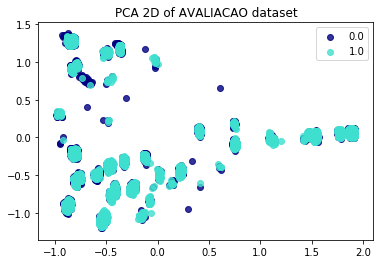

In [20]:
pca = PCA(n_components=2)
X_r = pca.fit_transform(X_train)

colors = ['navy', 'turquoise']
for color, i, target_name in zip(colors, [0, 1], y):
    plt.scatter(X_r[y_train == i, 0], X_r[y_train == i, 1], color=color, alpha=.8, label=target_name)
plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('PCA 2D of AVALIACAO dataset')

## Execução do PCA 3D para redução de dimensionalidade e verificação da distribuição dos dados
### Realmente os dados estão bem agrupados, aparentemente não são linearmente separáveis, será preciso usar técnicas para classificação de dados não linearmente separáveis para tentar melhorar os resultados.

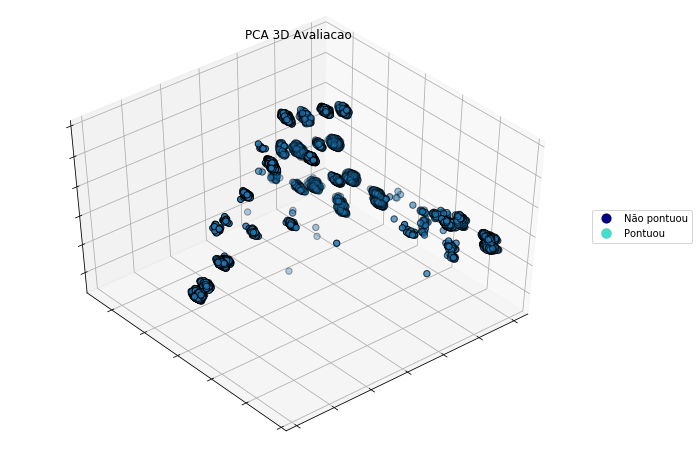

In [21]:
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3)
X_r = pca.fit_transform(X_train)

fig = plt.figure(1, figsize=(8, 6))
#ax = Axes3D(fig, rect=[0, 0, .7, 1], elev=48, azim=134)
ax = Axes3D(fig, elev=45, azim=50)
ax.scatter(X_r[:,0],X_r[:,1],X_r[:,2], cmap=plt.cm.Set1, edgecolor='k', s=40)

ax.set_title('PCA 3D Avaliacao')

ax.w_xaxis.set_ticklabels([])
ax.w_yaxis.set_ticklabels([])
ax.w_zaxis.set_ticklabels([])

labelTups = [('Não pontuou', 0), ('Pontuou', 1)]
custom_lines = [plt.Line2D([],[], ls="", marker='.', 
                mec='k', mfc=c, mew=.1, ms=20) for c in colors]
ax.legend(custom_lines, [lt[0] for lt in labelTups], 
          loc='center left', bbox_to_anchor=(1.0, .5))

plt.show()

## Aqui foi usado para a classificação árvores, florestas e ExtraTreesClassifier que usa florestas aleatórias, e foram comparados os resultados
### Foi testado com 10,100 e 1000 estimadores, apesar do melhor resultado ter sido com 1000 estimadores mas com uma melhora de menos de 1%, demorou bem mais para rodar, no final o melhor resultado foi o random forest com 100 estimadores, que ficou com 66,73% de acurácia

In [ ]:
print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))
model = DecisionTreeClassifier(max_depth=None, min_samples_split=2, random_state=0)
scores = cross_val_score(model, X_train, y_train, cv=10)
print('Acurácia de Decision Tree puro:', scores.mean())

model = RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_split=2, random_state=0)
scores = cross_val_score(model, X_train, y_train, cv=10)
print('Acurácia de Random Forest:', scores.mean())

model = ExtraTreesClassifier(n_estimators=100, max_depth=None, min_samples_split=2, random_state=0)
scores = cross_val_score(model, X_train, y_train, cv=10)
print('Acurácia de Extreme Randomized Trees:', scores.mean())
dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

## Aqui foi usado o ensemble, que usa vários classificadores individuais e depois usa todos eles juntos para a classificação, e compara os resultados
### Foi testado os classificadores: regressão logística, floresta randômica, gaussiano e KNN, com 10 e 1000 estimadores, mas com 1000 demorou bem mais e melhorou em apenas 1% em todos os classificadores, com exeção do regressão logística que se manteve em 68,37% de acurácia, tanto em 10 quanto em 1000 classificadores

In [ ]:
#por voto
print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))

clf1 = LogisticRegression(solver='lbfgs', multi_class='multinomial', random_state=1)
clf2 = RandomForestClassifier(n_estimators=1000, random_state=1)
clf3 = GaussianNB()
clf4 = KNeighborsClassifier()


eclf = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('gnb', clf3), ('KNN',clf4)], voting='hard')

for clf, label in zip([clf1, clf2, clf3,clf4,eclf], ['Logistic Regression', 'Random Forest', 'naive Bayes','KNN', 'Ensemble']):
    scores = cross_val_score(clf, X_train, y_train, cv=10)
    print("Acurácia: %0.4f (+/- %0.2f) [%s]" % (scores.mean(), scores.std(), label))
    
print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))

## Aqui foi usado GridSearchCV que separa 5% dos dados de treino para encontrar o melhor valor de K e o melhor classificador antes de fazer a validação cruzada e avaliar o modelo
### O melhor resultado em um range de 1 à 5 foi o classificador a distância, com o K=5 e acurácia de 62,27% e um desvio padrão de 0,81 , mas demorou quase duas horas para rodar.

In [ ]:
print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))

# separa-se uma parcela para encontrar os melhores parâmetros (5% do original)
data_gs, data_cv, target_gs, target_cv = train_test_split(X, y, test_size=0.95, random_state=42, stratify=y)

pipeline = Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier())])

# utiliza-se GridSearchCV para achar os melhores parâmetros

parameters = {'clf__n_neighbors': [1,2,3,4,5], 'clf__weights' : ['uniform','distance'] } # quais parâmetros(de K e de classificador) e quais valores serão testados
clf = GridSearchCV(pipeline, parameters, cv=3, iid=False) # clf vai armazenar qual foi a melhor configuração
clf.fit(data_gs,target_gs)

print(clf.best_estimator_)

# utilizando validação cruzada para avaliar o modelo
scores = cross_val_score(clf, data_cv, target_cv, cv=5)

print('Accuracy - %.2f +- %.2f' % (scores.mean() * 100, scores.std() * 100))

dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

## Aqui foi usado a seleção de atributos para reduzir a quantidade de atributos e ver se melhora o resultado, desempenho ou ambos
### Neste caso ele roda rápido com a quantidade original de atributos, então se diminuir os atributos só diminui a acurácia

In [ ]:
#seleção

for i in range(30,121,10):
    fvalue_selector = SelectKBest(f_classif, k=i)#K=qts atributos vai pegar
    X_kbest = fvalue_selector.fit_transform(X_train, y_train)#treina e aprende com os dados de treino

    print('Número original de atributos:', X.shape[1])
    print('Número reduzido de atributos:', X_kbest.shape[1])

    model = LogisticRegression(solver='lbfgs', multi_class='multinomial', max_iter=2000)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print('Acurácia nos dados originais:', accuracy_score(y_test,y_pred))

    model = LogisticRegression(solver='lbfgs', multi_class='multinomial', max_iter=2000)
    model.fit(X_kbest, y_train)
    X_test_kbest = fvalue_selector.transform(X_test)
    y_pred = model.predict(X_test_kbest)
    print('Acurácia nos dados X_kbest:  ', accuracy_score(y_test,y_pred))

## Aqui foi usado o GradientBoostingClassifier que ajusta as árvores de regressão ao gradiente negativo
### Até aqui foi o melhor resultado, com 100 parâmetros e profundidade = 1 deu uma acurácia de 68,42%, também foi testado com dados de teste onde com os mesmos parâmetros a acurácia ficou em 67,22%

In [22]:
for i in range(1,4):
    print(f'Profundidade = {i}')
    for j in range(100,501,100):
        model = GradientBoostingClassifier(n_estimators=j, learning_rate=0.3, max_depth=i, random_state=0)
        scores = cross_val_score(model, X, y, cv=5)

        print(f'Acurácia de Gradient Boosting Tree com {j} estimadores: ', scores.mean())


Profundidade = 1
Acurácia de Gradient Boosting Tree com 100 estimadores:  0.6778604067620538
Acurácia de Gradient Boosting Tree com 200 estimadores:  0.6779382202021166
Acurácia de Gradient Boosting Tree com 300 estimadores:  0.6776268907257615
Acurácia de Gradient Boosting Tree com 400 estimadores:  0.6773934125475214
Acurácia de Gradient Boosting Tree com 500 estimadores:  0.6771988600183384
Profundidade = 2
Acurácia de Gradient Boosting Tree com 100 estimadores:  0.6705835061553407
Acurácia de Gradient Boosting Tree com 200 estimadores:  0.6542385950725473


KeyboardInterrupt: 

## Aqui foi usado o suport vector classifier, e sua acurácia foi de 67%

In [ ]:
clf = SVC(gamma='auto')
clf.fit(X_train, y_train) 
y_pred_class = clf.predict(X_test)

recall = recall_score(y_test, y_pred_class)
accuracy = accuracy_score(y_test, y_pred_class)
precision =  precision_score(y_test, y_pred_class)

print('---')
print(f'Acurácia: {round(accuracy, 6)}%')
print(f'Recall: {round(recall, 6)}%')
print(f'Precisão: {round(precision, 6)}%')

print(clf.predict(X_test))

print('---')
print('Matriz de Confusão')
display(pd.DataFrame(confusion_matrix(y_test, y_pred_class)))
print('---')
        

## Aqui foi usado o bagging, onde usa vários KNNs para classificar e compara o melhor resultado
### Foi feito com um range de 10 à 50 com passo de 5 estimadores, a acurácia do KNN simples foi de 62,44% e do bagging o melhor resultado foi com 40 estimadores, 66.87%, após isso começou a cair e demorou mais de uma hora para rodar.

In [ ]:
model = KNeighborsClassifier()
scores = cross_val_score(model, X_train, y_train, cv=5)

print('Acurácia de KNeighbors simples:', scores.mean())

for i in range(10,51,5):
    model = BaggingClassifier(KNeighborsClassifier(), max_samples=0.5, max_features=0.5, n_estimators=i)#estimador=qts knns
    scores = cross_val_score(model, X_train, y_train, cv=5)

    print(f'Acurácia de KNeighbors Bagging (c/ {i} estimators):', scores.mean())

# CONCLUSÃO

## Após ter feito testes com vários algorítimos de classificação com vários parâmetros diferentes, os melhores classificadores foram o GradientBoostingClassifier com 68,42% de acurácia, e o logisticRegression com 68,37% e um logloss de 0,61.